In [5]:
import numpy as np
import ot_utils
import comparison_utils
from tqdm import tqdm
import math
import matplotlib.pyplot as plt

n_classes = 8
labels = np.repeat(np.arange(8), 1000)

w2_block_files = []
sw2_block_files = []

for i in range(n_classes):
    for j in range(i, n_classes):
        w2_block_files.append(f"../../mini_w2/block_{i}_{j}.npy")

for i in range(n_classes):
    for j in range(i, n_classes):
        sw2_block_files.append(f"../../mini_sw/block_{i}_{j}_sw2.npy")

w2_matrix = ot_utils.combine_distance_blocks(w2_block_files)
sw2_matrix = ot_utils.combine_distance_blocks(sw2_block_files)

In [3]:
w2_rel_rep, sw2_rel_rep = comparison_utils.relative_rep(
    w2_matrix, sw2_matrix, labels, n_classes, anchors_per_class=10, seed=1
)

In [ ]:
row_norms_w2 = np.linalg.norm(w2_rel_rep, axis=1, keepdims=True)
row_norms_sw2 = np.linalg.norm(sw2_rel_rep, axis=1, keepdims=True)

max_norm_w2 = np.max(row_norms_w2)
max_norm_sw2 = np.max(row_norms_sw2)

normalized_w2_rel_rep = w2_rel_rep / max_norm_w2
normalized_sw2_rel_rep = sw2_rel_rep / max_norm_sw2

In [ ]:
# #   angle = arctan( |v_d| / ||v_parallel|| )
# perp_comp    = w2_rel_rep[:, -1]                        # the component orthogonal to the plane
# parallel_norm = np.linalg.norm(w2_rel_rep[:, :-1], axis=1)  # norm of the projection onto the plane
# angles_rad   = np.arctan2(np.abs(perp_comp), parallel_norm)
# angles_deg   = np.degrees(angles_rad)

# plt.hist(angles_deg, bins=100)
# plt.show()

In [ ]:
# #   angle = arctan( |v_d| / ||v_parallel|| )
# perp_comp    = sw2_rel_rep[:, -1]                        # the component orthogonal to the plane
# parallel_norm = np.linalg.norm(w2_rel_rep[:, :-1], axis=1)  # norm of the projection onto the plane
# angles_rad   = np.arctan2(np.abs(perp_comp), parallel_norm)
# angles_deg   = np.degrees(angles_rad)

# plt.hist(angles_deg, bins=100)
# plt.show()

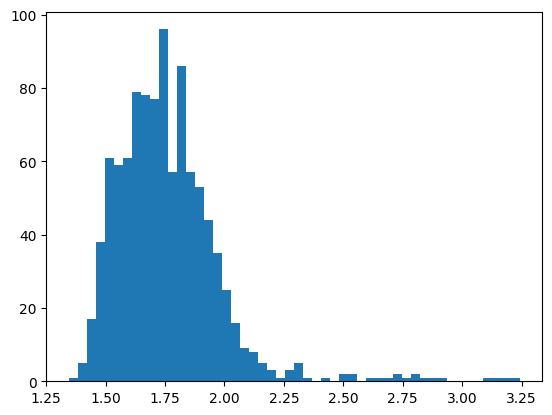

In [51]:
plt.hist(row_norms_w2[1000:2000], bins=50)
plt.show()

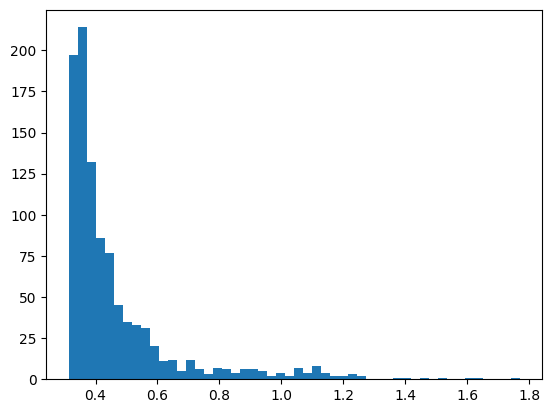

In [50]:
plt.hist(row_norms_sw2[1000:2000], bins=50)
plt.show()

In [7]:
n_samples = 8000
w2_pairwise_euc_sim = np.zeros((n_samples, n_samples))
sw2_pairwise_euc_sim = np.zeros((n_samples, n_samples))

w2_pairwise_tanimoto_sim = np.zeros((n_samples, n_samples))
sw2_pairwise_tanimoto_sim = np.zeros((n_samples, n_samples))

w2_pairwise_cos_sim = np.zeros((n_samples, n_samples))
sw2_pairwise_cos_sim = np.zeros((n_samples, n_samples))

i_pairs, j_pairs = np.triu_indices(n_samples, k=1)

for i, j in tqdm(zip(i_pairs, j_pairs), total=len(i_pairs)):
    w2_pairwise_euc_sim[i, j] = comparison_utils.eud_sim_2(
        normalized_w2_rel_rep[i], normalized_w2_rel_rep[j]
    )
    w2_pairwise_euc_sim[j, i] = w2_pairwise_euc_sim[i, j]

    sw2_pairwise_euc_sim[i, j] = comparison_utils.eud_sim_2(
        normalized_sw2_rel_rep[i], normalized_sw2_rel_rep[j]
    )
    sw2_pairwise_euc_sim[j, i] = sw2_pairwise_euc_sim[i, j]

    w2_pairwise_tanimoto_sim[i, j] = comparison_utils.tanimoto_sim(
        w2_rel_rep[i], w2_rel_rep[j]
    )
    w2_pairwise_tanimoto_sim[j, i] = w2_pairwise_tanimoto_sim[i, j]

    sw2_pairwise_tanimoto_sim[i, j] = comparison_utils.tanimoto_sim(
        sw2_rel_rep[i], sw2_rel_rep[j]
    )
    sw2_pairwise_tanimoto_sim[j, i] = sw2_pairwise_tanimoto_sim[i, j]

100%|██████████| 31996000/31996000 [03:32<00:00, 150314.94it/s]


In [10]:
qcd_i, qcd_j = np.triu_indices(1000, k=1)

class_1_i = qcd_i + 0000
class_1_j = qcd_j + 0000

w2_class_1_tanimoto_sims = w2_pairwise_tanimoto_sim[class_1_i, class_1_j]
sw2_class_1_tanimoto_sims = sw2_pairwise_tanimoto_sim[class_1_i, class_1_j]

print(w2_class_1_tanimoto_sims.mean())
print(sw2_class_1_tanimoto_sims.mean())

0.9765694376135042
0.8809287723807955


In [45]:
n_classes = 8
class_size = 1000

# prepare the output
avg_sim = np.zeros((n_classes, n_classes), dtype=float)

for i in range(n_classes):
    # row‐slice for class i
    start_i = i * class_size
    end_i   = start_i + class_size

    for j in range(i, n_classes):
        # col‐slice for class j
        start_j = j * class_size
        end_j   = start_j + class_size

        block = w2_pairwise_tanimoto_sim[start_i:end_i, start_j:end_j]

        if i == j:
            # only upper‐triangle, exclude diagonal
            iu, ju = np.triu_indices(class_size, k=1)
            vals = block[iu, ju]
        else:
            # include every entry in this off-diagonal block
            vals = block.ravel()

        mean_val = vals.mean()
        avg_sim[i, j] = mean_val
        avg_sim[j, i] = mean_val  # symmetry

# now `avg_sim` is your 8×8 matrix of mean similarities

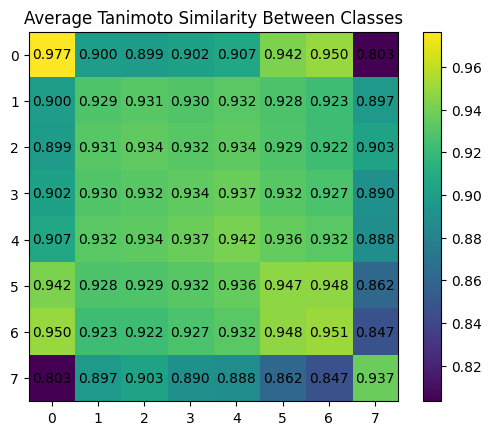

In [46]:
fig, ax = plt.subplots()
im = ax.imshow(avg_sim)

# Annotate each cell with its value
for i in range(avg_sim.shape[0]):
    for j in range(avg_sim.shape[1]):
        ax.text(j, i, f"{avg_sim[i, j]:.3f}", ha='center', va='center')

# Label axes with class names
ax.set_xticks(np.arange(avg_sim.shape[1]))
ax.set_yticks(np.arange(avg_sim.shape[0]))
ax.set_xticklabels([f"{i}" for i in range(avg_sim.shape[1])])
ax.set_yticklabels([f"{i}" for i in range(avg_sim.shape[0])])

plt.colorbar(im, ax=ax)
plt.title("Average Tanimoto Similarity Between Classes")
plt.show()

In [47]:
i_ind, j_ind = np.triu_indices(8, k=0)

w2_distinguishability = 0
for i, j in zip(i_ind, j_ind):
    if i == j:
        sim = avg_sim[i, j]
    else:
        sim = 1 - avg_sim[i, j]
    
    w2_distinguishability += sim

avg_w2_distinguishability = w2_distinguishability / 36
print(avg_w2_distinguishability)

0.2773899667556845


In [48]:
n_classes = 8
class_size = 1000

# prepare the output
avg_sim = np.zeros((n_classes, n_classes), dtype=float)

for i in range(n_classes):
    # row‐slice for class i
    start_i = i * class_size
    end_i   = start_i + class_size

    for j in range(i, n_classes):
        # col‐slice for class j
        start_j = j * class_size
        end_j   = start_j + class_size

        block = sw2_pairwise_tanimoto_sim[start_i:end_i, start_j:end_j]

        if i == j:
            # only upper‐triangle, exclude diagonal
            iu, ju = np.triu_indices(class_size, k=1)
            vals = block[iu, ju]
        else:
            # include every entry in this off-diagonal block
            vals = block.ravel()

        mean_val = vals.mean()
        avg_sim[i, j] = mean_val
        avg_sim[j, i] = mean_val  # symmetry

# now `avg_sim` is your 8×8 matrix of mean similarities

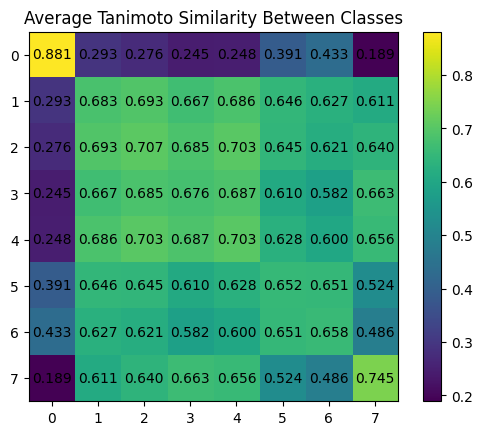

In [49]:
fig, ax = plt.subplots()
im = ax.imshow(avg_sim)

# Annotate each cell with its value
for i in range(avg_sim.shape[0]):
    for j in range(avg_sim.shape[1]):
        ax.text(j, i, f"{avg_sim[i, j]:.3f}", ha='center', va='center')

# Label axes with class names
ax.set_xticks(np.arange(avg_sim.shape[1]))
ax.set_yticks(np.arange(avg_sim.shape[0]))
ax.set_xticklabels([f"{i}" for i in range(avg_sim.shape[1])])
ax.set_yticklabels([f"{i}" for i in range(avg_sim.shape[0])])

plt.colorbar(im, ax=ax)
plt.title("Average Tanimoto Similarity Between Classes")
plt.show()

In [50]:
i_ind, j_ind = np.triu_indices(8, k=0)

sw2_distinguishability = 0
for i, j in zip(i_ind, j_ind):
    if i == j:
        sim = avg_sim[i, j]
    else:
        sim = 1 - avg_sim[i, j]
    
    sw2_distinguishability += sim

avg_sw2_distinguishability = sw2_distinguishability / 36
print(avg_sw2_distinguishability)

0.5088318193323931


In [32]:
row_norms_w2 = np.linalg.norm(w2_rel_rep, axis=1, keepdims=True)
row_norms_sw2 = np.linalg.norm(sw2_rel_rep, axis=1, keepdims=True)

normalized_w2_rel_rep = w2_rel_rep / row_norms_w2
normalized_sw2_rel_rep = sw2_rel_rep / row_norms_sw2

(8000, 8000)
(8000, 8000)


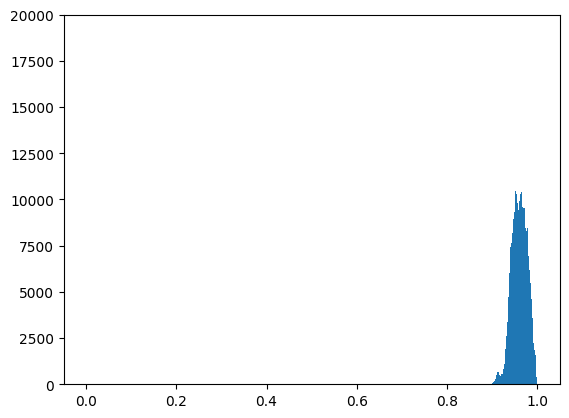

In [66]:
w2_pairwise_cos_sim = normalized_w2_rel_rep @ normalized_w2_rel_rep.T
sw2_pairwise_cos_sim = normalized_sw2_rel_rep @ normalized_sw2_rel_rep.T
print(sw2_pairwise_cos_sim.shape)
print(w2_pairwise_cos_sim.shape)

qcd_i, qcd_j = np.triu_indices(1000, k=1)
class_1_i = qcd_i + 0000
class_1_j = qcd_j + 1000

w2_class_1_cos_sims = w2_pairwise_cos_sim[class_1_i, class_1_j]
sw2_class_1_cos_sims = sw2_pairwise_cos_sim[class_1_i, class_1_j]

# w2_class_1_cos_sims = np.arccos(w2_class_1_cos_sims)
# sw2_class_1_cos_sims = np.arccos(sw2_class_1_cos_sims)

plt.ylim(0, 20000)
plt.hist(w2_class_1_cos_sims, bins=1000, range=(0,1))
plt.show()

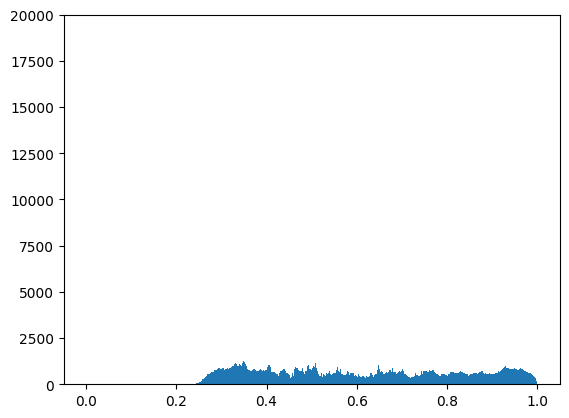

In [67]:
plt.ylim(0, 20000)
plt.hist(sw2_class_1_cos_sims, bins=1000, range=(0,1))
plt.show()

In [ ]:
from sklearn.metrics import pairwise_distances

pairwise_eud_sims_w2_sw2 = pairwise_distances(
    normalized_w2_rel_rep,
    normalized_sw2_rel_rep,
    metric=lambda u, v: comparison_utils.eud_sim(u, v),
    n_jobs=-1,  # use all CPUs to parallelize
)

pairwise_cos_sims_w2_sw2 = pairwise_distances(
    normalized_w2_rel_rep,
    normalized_sw2_rel_rep,
    metric=lambda u, v: comparison_utils.cos_sim(u, v),
    n_jobs=-1,
)

print(pairwise_eud_sims_w2_sw2.shape)

(8000, 8000)


In [8]:
rows, cols = np.indices((1000, 1000))

i = 0
rows = rows + 1000 * i
cols = cols + 1000 * i

w2_sw2_qcd_eud_sims = pairwise_eud_sims_w2_sw2[rows, cols]
w2_sw2_qcd_cos_sims = pairwise_cos_sims_w2_sw2[rows, cols]

print(w2_sw2_qcd_eud_sims.mean())
print(w2_sw2_qcd_cos_sims.mean())

0.6804385102842498
0.8960722101138022
